# Visualizing Fire Scars through False Color Imagery

## EDS 220: Homework 4 - Task 2

**Author:** Sarah Hinkley

**GitHub Repository:** https://github.com/sarahhinkley/eds220-hwk4.git


### 1. Reading

Read the following resources about false color images and Landsat imagery:

[Why is that Forest Red and that Cloud Blue? How to Interpret a False-Color Satellite Image](https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/)

[What are the band designations for the Landsat satellites?](https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites)

[Common Landsat Band Combinations](https://www.usgs.gov/media/images/common-landsat-band-combinations)

In [23]:
import os
import geopandas as gpd
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Import fire perimeters
eaton = gpd.read_file(os.path.join('data', 
                                    'Eaton_Perimeter_20250121', 
                                   'Eaton_Perimeter_20250121.shp'))
palisades = gpd.read_file(os.path.join('data',
                                      'Palisades_Perimieter_20250121',
                                      'Palisades_Perimieter_20250121.shp'))

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


### 2. Fire perimeter data exploration

Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic. 

In [43]:
print(f'The palisades shapefile contains {palisades.shape[0]} multipolygon.')
print(f'The eaton shapefile contains {eaton.shape[0]} multipolygon.')

The palisades shapefile contains 1 multipolygon.
The eaton shapefile contains 1 multipolygon.


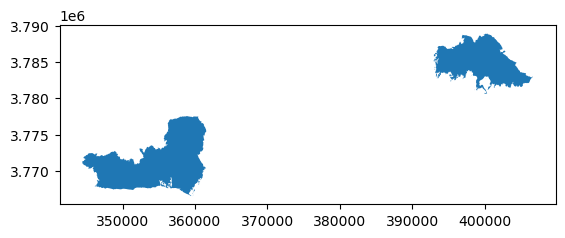

In [45]:

fig, ax = plt.subplots()

eaton.plot(ax=ax)
palisades.plot(ax=ax)

plt.show()

In [5]:
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [6]:
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

**Summary from preliminary data exploration:** 

### 3. NetCDF data import and exploration

a. Import the Landsat data using `xr.open_dataset()`.

In [7]:
# Import landsat data 
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

sh: 1: getfattr: not found


b. Explore the data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include a description of the data’s variables, dimensions, and coordinates.

In [8]:
landsat.sizes

Frozen({'y': 1418, 'x': 2742})

In [9]:
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

### 4. Restoring geospatial information

a. Use `rio.crs` to print the CRS of this dataset. Is this a geospatial object?

In [10]:
print(landsat.rio.crs)

None


This is not a geospatial object. 

b. You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable `spatial_ref`. Print the CRS by accessing the `spatial_ref.crs_wkt` attribute of the dataset.

In [11]:
landsat_crs = landsat.spatial_ref.crs_wkt
landsat_crs

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

c. Recover the geospatial information by using `rio.write_crs()` and the spatial reference information from part b.

In [12]:
landsat = landsat.rio.write_crs(landsat_crs)

d. Print the CRS of the updated dataset.

In [13]:
print(landsat.rio.crs)

EPSG:32611


### 5. True color image

a. Without creating any new variables:
- select the red, green, and blue variables (in that order) of the `xarray.Dataset` holding the Landsat data,
- convert it to an `xarray.DataArray` using the `to_dataarray()` method, and then
- use `.plot.imshow()` to create an RGB image with the data. There will be a warning; that’s ok.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


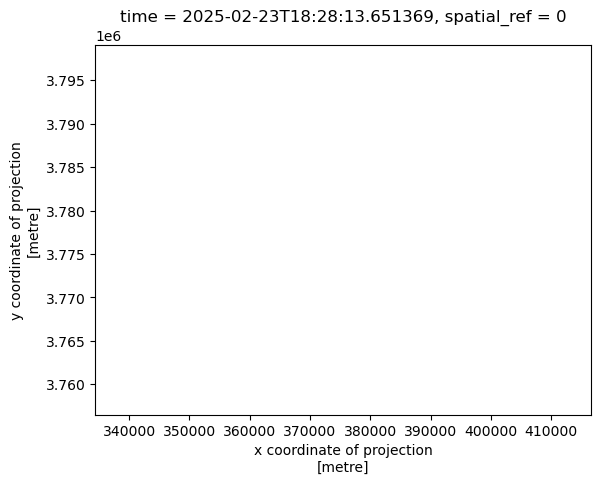

In [14]:
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()
plt.show()

b. Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


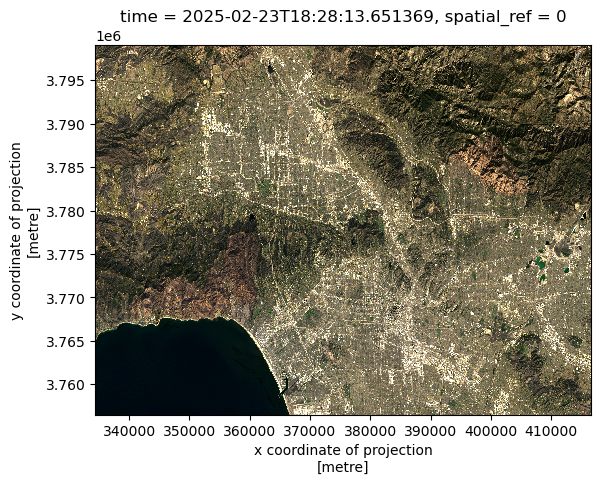

In [15]:
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)
plt.show()

c. To resolve the other warning, identify which bands have `nan` values. HINT: There are many ways of doing so. One option is to use `numpy.isnan()`.

In [16]:
landsat_bands = ['red', 'green', 'blue', 'nir08', 'swir22']

for band in landsat_bands:
    na_values = int(np.isnan(landsat[band]).sum())
    print(f'{band} has {na_values} NA values.')

red has 0 NA values.
green has 1 NA values.
blue has 109 NA values.
nir08 has 0 NA values.
swir22 has 0 NA values.


d. Use the `.fillna()` method for `xarray.Datasets` to replace any nan values in the Landsat data with zero.

In [17]:
landsat = landsat.fillna(value=0)

In [18]:
# Check updating the NAs to Os worked
for band in landsat_bands:
    assert int(np.isnan(landsat[band]).sum()) == 0, f"{band} still has NA values"

e. Create a new true color image that gets plotted without warnings.

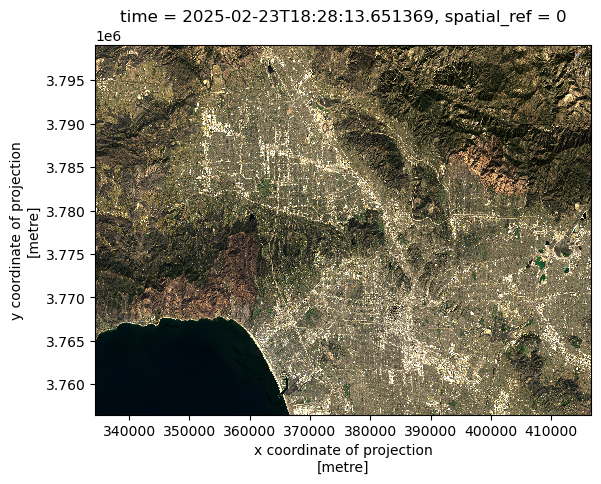

In [19]:
landsat[['red','green','blue']].to_dataarray().plot.imshow(robust=True)
plt.show()

f. In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e).

### 6. False color image

Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order).

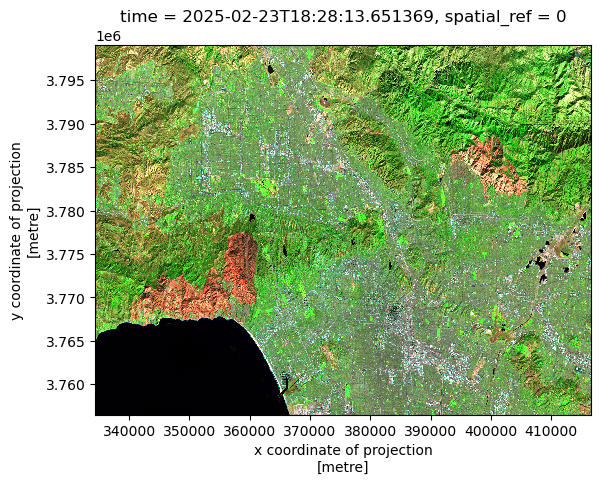

In [20]:
landsat[['swir22','nir08','red']].to_dataarray().plot.imshow(robust=True)
plt.show()

### 7. Map

a. Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire *perimeters*. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

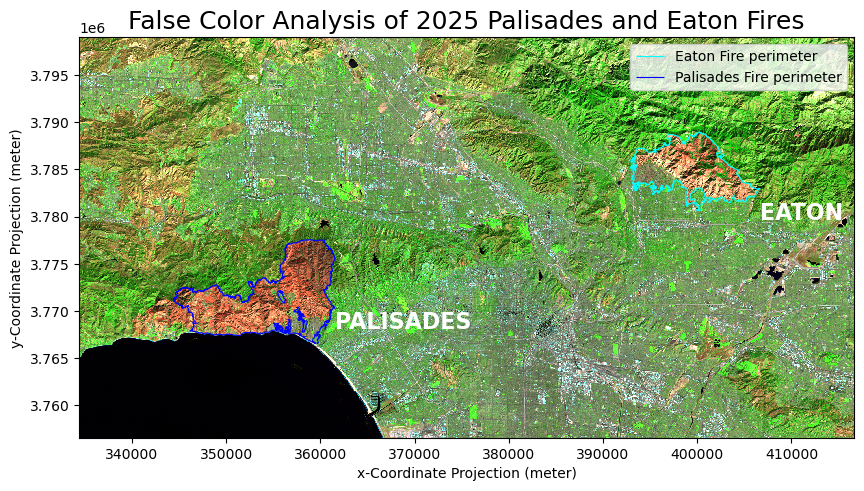

In [32]:
# Update fire perimeter CRS to match Landsat CRS
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

# Finding max coordinates of fire polygons
eaton_max = eaton.geometry.get_coordinates().max()
palisades_max = palisades.geometry.get_coordinates().max()

# Max coords
max_x = [eaton_max.iloc[0], palisades_max.iloc[0]]
max_y = [eaton_max.iloc[1], palisades_max.iloc[1]]

# Create map to combine landsat data and fire perimeters
fig, ax = plt.subplots(figsize=(10,8))

# Plot false color composite
landsat[['swir22','nir08','red']].to_dataarray().plot.imshow(ax = ax, robust=True)
 
# Overlay Palisades and Eaton fire perimeters
eaton.boundary.plot(ax=ax, edgecolor='aqua', linewidth=0.8, label='Eaton Fire perimeter')
palisades.boundary.plot(ax=ax, edgecolor='blue', linewidth=0.8, label='Palisades Fire perimeter')

# Add title, x/y axes labels, and legend
ax.set_title('False Color Analysis of 2025 Palisades and Eaton Fires', fontsize = 18)
plt.xlabel('x-Coordinate Projection (meter)')
plt.ylabel('y-Coordinate Projection (meter)')
plt.legend()

# Add fire name annotations
combined_fires = pd.concat([eaton, palisades])
for x, y, name in zip(max_x, max_y, combined_fires['FIRE_NAME']):
    ax.text(x,y-7500,name, fontsize=16, ha='left', va = 'top', color= 'white', fontweight='bold')

plt.show()

b. Write a figure description for the map including a brief explanation of how false color imagery is being used.